# CICIDS2017 Multi-Class Classification (V2 — Improved Pipeline)

Improvements over V1:
1. Duplicate row removal
2. Rare attack classes grouped into meta-categories
3. Zero-variance and highly correlated features removed
4. RobustScaler for outlier-resistant scaling
5. Class-balanced training for all models

In [1]:
import pandas as pd
import numpy as np
import glob
import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading & Cleaning

In [2]:
files = glob.glob(r'../Datasets/CICIDS/*.csv')
print(f"Found {len(files)} CSV files.")

df_list = []
for f in files:
    sub_df = pd.read_csv(f)
    df_list.append(sub_df)

df = pd.concat(df_list, ignore_index=True)
df.columns = df.columns.str.strip()
df['Label'] = df['Label'].astype(str).str.strip().str.encode('ascii', 'ignore').str.decode('utf-8')
df['Label'] = df['Label'].replace('', 'UNKNOWN')

# Drop non-predictive identifier columns
drop_cols = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Timestamp', 'Destination Port']
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Clean Inf/NaNs
df = df.replace([np.inf, -np.inf], np.nan).dropna()

# NEW: Drop duplicate rows
original_len = len(df)
df = df.drop_duplicates()
print(f"Dropped {original_len - len(df)} duplicate rows.")

print("Processed Dataset Shape:", df.shape)
print("\nTarget Class Distribution (Before Grouping):\n", df['Label'].value_counts())

Found 8 CSV files.
Dropped 594712 duplicate rows.
Processed Dataset Shape: (2233164, 78)

Target Class Distribution (Before Grouping):
 Label
BENIGN                       1896672
DoS Hulk                      172846
DDoS                          128014
DoS GoldenEye                  10286
FTP-Patator                     5931
DoS slowloris                   5385
DoS Slowhttptest                5228
SSH-Patator                     3219
PortScan                        1956
Web Attack  Brute Force         1470
Bot                             1437
Web Attack  XSS                  652
Infiltration                      36
Web Attack  Sql Injection         21
Heartbleed                        11
Name: count, dtype: int64


## 2. Group Rare Attack Classes

We merge related sub-attacks into broader categories to ensure each class has enough samples for meaningful learning.

In [3]:
# Group related attacks into meta-categories
label_map = {
    'Web Attack  Brute Force': 'Web Attack',
    'Web Attack  XSS': 'Web Attack',
    'Web Attack  Sql Injection': 'Web Attack',
    'DoS Hulk': 'DoS',
    'DoS GoldenEye': 'DoS',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
    'FTP-Patator': 'Brute Force',
    'SSH-Patator': 'Brute Force',
}
df['Label'] = df['Label'].replace(label_map)

# Drop classes with fewer than 50 samples (statistically unreliable)
min_samples = 50
class_counts = df['Label'].value_counts()
valid_labels = class_counts[class_counts >= min_samples].index
removed_labels = class_counts[class_counts < min_samples]
if len(removed_labels) > 0:
    print(f"Removing classes with < {min_samples} samples: {list(removed_labels.index)}")
df = df[df['Label'].isin(valid_labels)]

print("\nTarget Class Distribution (After Grouping):")
print(df['Label'].value_counts())
print(f"\nFinal number of classes: {df['Label'].nunique()}")
print(f"Final dataset shape: {df.shape}")

Removing classes with < 50 samples: ['Infiltration', 'Heartbleed']

Target Class Distribution (After Grouping):
Label
BENIGN         1896672
DoS             193745
DDoS            128014
Brute Force       9150
Web Attack        2143
PortScan          1956
Bot               1437
Name: count, dtype: int64

Final number of classes: 7
Final dataset shape: (2233117, 78)


## 3. Feature Selection

Remove zero-variance and highly correlated features to reduce noise and dimensionality.

In [4]:
X = df.drop(columns=['Label'])
y = df['Label']

# Step 1: Remove zero/near-zero variance features
print(f"Features before variance filter: {X.shape[1]}")
vt = VarianceThreshold(threshold=0.01)
X_filtered = pd.DataFrame(vt.fit_transform(X), columns=X.columns[vt.get_support()], index=X.index)
removed_variance = set(X.columns) - set(X_filtered.columns)
if removed_variance:
    print(f"Removed {len(removed_variance)} near-zero variance features: {removed_variance}")
else:
    print("No near-zero variance features found.")
X = X_filtered

# Step 2: Remove highly correlated features (|r| > 0.95)
print(f"\nFeatures before correlation filter: {X.shape[1]}")
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_cols = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]
if high_corr_cols:
    print(f"Removing {len(high_corr_cols)} highly correlated features (|r| > 0.95):")
    for col in high_corr_cols:
        print(f"  - {col}")
    X = X.drop(columns=high_corr_cols)
else:
    print("No highly correlated features found.")

print(f"\nFinal feature count: {X.shape[1]}")

Features before variance filter: 77
Removed 12 near-zero variance features: {'Bwd Avg Packets/Bulk', 'Fwd Avg Packets/Bulk', 'Bwd URG Flags', 'Bwd Avg Bytes/Bulk', 'RST Flag Count', 'Fwd Avg Bulk Rate', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'ECE Flag Count', 'Bwd Avg Bulk Rate', 'Fwd URG Flags', 'Bwd PSH Flags'}

Features before correlation filter: 65
Removing 21 highly correlated features (|r| > 0.95):
  - Total Backward Packets
  - Total Length of Bwd Packets
  - Fwd Packet Length Std
  - Bwd Packet Length Mean
  - Bwd Packet Length Std
  - Fwd IAT Total
  - Fwd IAT Max
  - Fwd Packets/s
  - Packet Length Std
  - SYN Flag Count
  - Average Packet Size
  - Avg Fwd Segment Size
  - Avg Bwd Segment Size
  - Fwd Header Length.1
  - Subflow Fwd Packets
  - Subflow Fwd Bytes
  - Subflow Bwd Packets
  - Subflow Bwd Bytes
  - Idle Mean
  - Idle Max
  - Idle Min

Final feature count: 44


## 4. Preprocessing & Train-Test Split

In [5]:
# Label Encode Target
target_encoder = LabelEncoder()
y_enc = target_encoder.fit_transform(y)

# Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=42
)

# Scale with RobustScaler (resistant to outliers, DL-ready)
scaler = RobustScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)
print("Classes:", list(target_encoder.classes_))

Train shape: (1786493, 44) Test shape: (446624, 44)
Classes: ['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'PortScan', 'Web Attack']


## 5. Model Training & Comparison (with Balanced Class Weights)

In [6]:
models = {
    "LightGBM (Balanced)": LGBMClassifier(
        n_estimators=200, class_weight='balanced',
        random_state=42, n_jobs=-1, verbose=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200, class_weight='balanced', random_state=42
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=100, class_weight='balanced_subsample',
        max_samples=0.3, random_state=42, n_jobs=-1
    ),
}

results = []
for name, model in models.items():
    print(f"Training {name}...")
    start = time.time()
    model.fit(X_train_scaled, y_train)
    elapsed = time.time() - start
    
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    w_f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
    m_f1 = f1_score(y_test, preds, average='macro', zero_division=0)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Weighted Precision': prec,
        'Weighted Recall': rec,
        'Weighted F1': w_f1,
        'Macro F1': m_f1,
        'Time (s)': elapsed
    })
    print(f"{name} - Acc: {acc:.4f}, Weighted F1: {w_f1:.4f}, Macro F1: {m_f1:.4f} ({elapsed:.1f}s)")

results_df = pd.DataFrame(results)
display(results_df)

Training LightGBM (Balanced)...
LightGBM (Balanced) - Acc: 0.7527, Weighted F1: 0.8297, Macro F1: 0.3926 (37.8s)
Training HistGradientBoosting...
HistGradientBoosting - Acc: 0.9970, Weighted F1: 0.9972, Macro F1: 0.9147 (31.7s)
Training Random Forest (Balanced)...
Random Forest (Balanced) - Acc: 0.9989, Weighted F1: 0.9989, Macro F1: 0.9441 (35.1s)


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Time (s)
0,LightGBM (Balanced),0.752673,0.947631,0.752673,0.829742,0.392649,37.764741
1,HistGradientBoosting,0.996977,0.997627,0.996977,0.997205,0.914711,31.675200
2,Random Forest (Balanced),0.998903,0.998882,0.998903,0.998869,0.944077,35.124702


## 6. Per-Class Performance (Best Model)

In [7]:
# Find best model by Macro F1
best_idx = results_df['Macro F1'].idxmax()
best_model_name = results_df.loc[best_idx, 'Model']
print(f"Best model by Macro F1: {best_model_name}")
print(f"Macro F1: {results_df.loc[best_idx, 'Macro F1']:.4f}")
print()

best_model = list(models.values())[best_idx]
preds = best_model.predict(X_test_scaled)
print(classification_report(y_test, preds, target_names=target_encoder.classes_, zero_division=0))

Best model by Macro F1: Random Forest (Balanced)
Macro F1: 0.9441

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    379335
         Bot       0.91      0.58      0.71       287
 Brute Force       1.00      0.98      0.99      1830
        DDoS       1.00      1.00      1.00     25603
         DoS       1.00      1.00      1.00     38749
    PortScan       0.93      0.94      0.93       391
  Web Attack       0.99      0.96      0.98       429

    accuracy                           1.00    446624
   macro avg       0.97      0.92      0.94    446624
weighted avg       1.00      1.00      1.00    446624



## 7. Visualizing Results

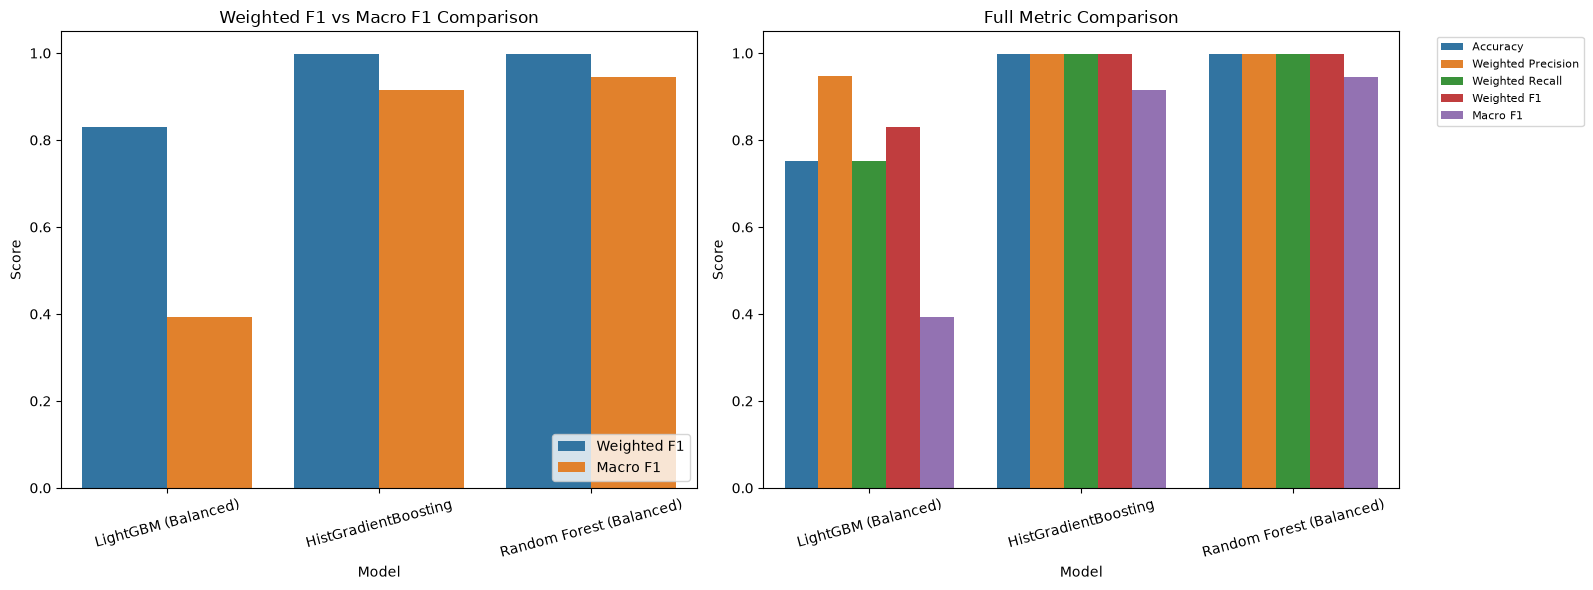

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Weighted vs Macro F1
melted_f1 = results_df.melt(id_vars='Model', value_vars=['Weighted F1', 'Macro F1'],
                            var_name='Metric', value_name='Score')
sns.barplot(data=melted_f1, x='Model', y='Score', hue='Metric', ax=axes[0])
axes[0].set_title('Weighted F1 vs Macro F1 Comparison')
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(loc='lower right')

# Plot 2: All metrics
melted_all = results_df.melt(id_vars='Model',
                             value_vars=['Accuracy', 'Weighted Precision', 'Weighted Recall', 'Weighted F1', 'Macro F1'],
                             var_name='Metric', value_name='Score')
sns.barplot(data=melted_all, x='Model', y='Score', hue='Metric', ax=axes[1])
axes[1].set_title('Full Metric Comparison')
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 8. Save Preprocessors & Results

In [9]:
import joblib

os.makedirs('../Models', exist_ok=True)
joblib.dump(scaler, '../Models/cicids_v2_scaler.pkl')
joblib.dump(target_encoder, '../Models/cicids_v2_label_encoder.pkl')
joblib.dump(vt, '../Models/cicids_v2_variance_filter.pkl')
results_df.to_csv('../Models/cicids_v2_results.csv', index=False)

print("Saved: scaler, label_encoder, variance_filter, results")
print("\nFeatures used:", list(X_train_scaled.columns))
print(f"\nHigh-corr columns removed: {high_corr_cols}")

Saved: scaler, label_encoder, variance_filter, results

Features used: ['Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Variance', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'Down/Up Ratio', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Std']

High-corr columns removed: ['Total Backward Packets', 'Total Length of Bwd Packets', 'Fw